# Challenge 2: Predicting online shopping purchases (CAI 4105, Team 8)

**Goal:** predict whether an online shopping session ends in a purchase (`Revenue = True`).
**Main metric:** F1 score of the positive class (a purchase). Only about 15% of sessions end in a purchase, so accuracy alone would be misleading.

**Workflow in this notebook**
1. Load the data and explore it
2. Preprocessing and feature engineering (shared code in `common.py`)
3. Validation strategy: one 5-fold stratified cross-validation used for every model
4. Compare the 7 required models (each one tuned with Grid Search) plus what we learned from each
5. Select the final model and justify the choice
6. Estimate how well it will do on new data (nested cross-validation)
7. Train the final model and write `predictions.csv`

The seven models were developed by different teammates in `models/*.py`. They all call the same `run_experiment` function in `common.py`, so the comparison is fair. Their saved results are in `results/*.json`. This notebook reads those results, then **re-computes the final model's validation live** and creates the predictions.

In [1]:
import sys, json, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30)

# works whether the notebook is opened from the repo root or from challenge2/
HERE = Path.cwd()
PROJECT = HERE if (HERE / "common.py").exists() else HERE / "challenge2"
sys.path.insert(0, str(PROJECT))

import common
from common import RANDOM_STATE, load_train, load_test, make_pipeline, cv_evaluate, get_cv
from summarize import comparison_table
print("Project folder:", PROJECT)

Project folder: /tmp/claude-0/-home-claude/d150e9fb-9de8-5906-9425-ff353e2b584e/scratchpad/verify_repo/challenge2


In [2]:
# Set to True only if you want to re-run all 7 model searches from scratch (about 30 to 40 minutes).
# By default we use the results the team already saved in results/*.json.
RERUN_ALL_MODELS = False

if RERUN_ALL_MODELS:
    for script in sorted((PROJECT / "models").glob("*.py")):
        if not script.name.startswith("_"):
            print("running", script.name)
            subprocess.run([sys.executable, str(script)], check=True)

## 1. Data and exploration

In [3]:
X, y = load_train()
X_test, test_ids = load_test()
print("Training sessions:", X.shape[0], "| features:", X.shape[1], "| test sessions:", X_test.shape[0])
print("Missing values (train / test):", int(X.isna().sum().sum()), "/", int(X_test.isna().sum().sum()))
print(f"Purchases in training data: {y.sum()} of {len(y)} = {y.mean():.1%}")
print(f"Always predicting 'no purchase' would be {1 - y.mean():.1%} accurate but would have F1 = 0.")
display(X.head())

Training sessions: 9247 | features: 17 | test sessions: 3083
Missing values (train / test): 0 / 0
Purchases in training data: 1431 of 9247 = 15.5%
Always predicting 'no purchase' would be 84.5% accurate but would have F1 = 0.


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False
2,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False
3,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False
4,0,0.0,0,0.0,2,37.000000,0.00,0.10,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False


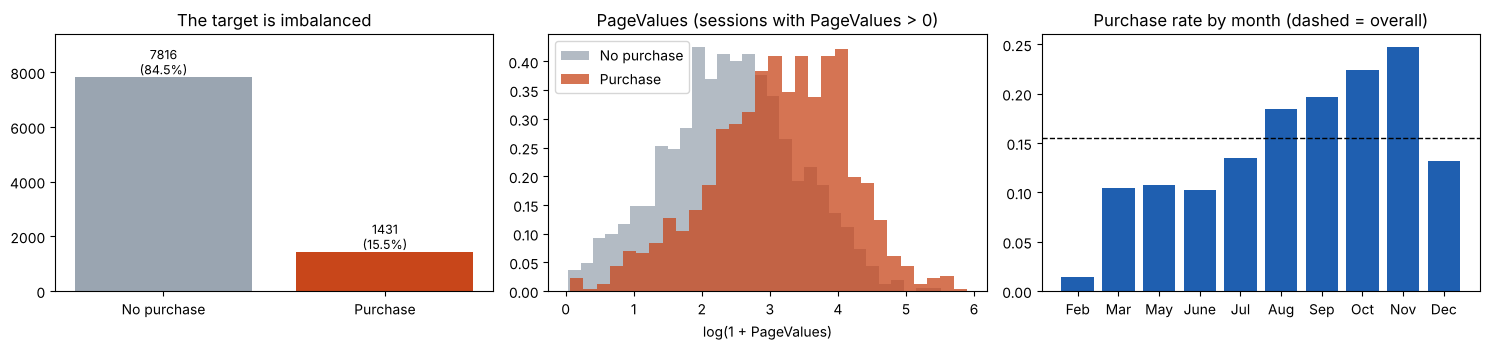

Sessions with PageValues > 0:  buyers 81.8%  vs  non-buyers 11.4%
                   purchase rate  count
VisitorType                            
New_Visitor                0.247   1265
Other                      0.181     72
Returning_Visitor          0.140   7910


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))

counts = y.value_counts().sort_index()
axes[0].bar(["No purchase", "Purchase"], counts.values, color=["#9aa5b1", "#c8461a"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v}\n({v / len(y):.1%})", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, counts.max() * 1.2); axes[0].set_title("The target is imbalanced")

pv = X["PageValues"]
for flag, color, label in [(0, "#9aa5b1", "No purchase"), (1, "#c8461a", "Purchase")]:
    axes[1].hist(np.log1p(pv[(y == flag) & (pv > 0)]), bins=30, alpha=.75, color=color, label=label, density=True)
axes[1].set_title("PageValues (sessions with PageValues > 0)"); axes[1].set_xlabel("log(1 + PageValues)"); axes[1].legend()

order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month = y.groupby(X["Month"]).mean().reindex(order)
axes[2].bar(order, by_month.values, color="#1f5fb0"); axes[2].axhline(y.mean(), ls="--", color="k", lw=1)
axes[2].set_title("Purchase rate by month (dashed = overall)")
plt.tight_layout(); plt.show()

share = (pv > 0).groupby(y).mean()
print(f"Sessions with PageValues > 0:  buyers {share[1]:.1%}  vs  non-buyers {share[0]:.1%}")
print(y.groupby(X["VisitorType"]).agg(["mean", "count"]).round(3).rename(columns={"mean": "purchase rate"}))

**What we learned from the data**
- Only 15.5% of sessions are purchases, so we use **F1 of the purchase class** and look at precision, recall and the confusion matrix, not accuracy.
- `PageValues` is the strongest signal: 82% of buyers have a value above 0, against 11% of non-buyers.
- Purchase rates change a lot by month (Nov and Oct are highest, Feb is almost zero) and by visitor type (new visitors buy more than returning ones).
- There are no missing values, and the test set contains no categories that are missing from the training set. 81 training rows are duplicates (ignoring `ID`); we kept them because they are real sessions (dropping them would change the training data without a clear reason).
- `ID` is not used as a predictor.

## 2. Preprocessing and feature engineering

In [5]:
import inspect
print(inspect.getsource(common.add_features))

def add_features(df):
    df = df.copy()
    df["TotalPages"] = df["Administrative"] + df["Informational"] + df["ProductRelated"]
    df["TotalDuration"] = (df["Administrative_Duration"] + df["Informational_Duration"]
                           + df["ProductRelated_Duration"])
    # average seconds spent per page (max(.,1) avoids dividing by zero)
    df["AvgTime_Product"] = df["ProductRelated_Duration"] / df["ProductRelated"].clip(lower=1)
    df["AvgTime_Admin"] = df["Administrative_Duration"] / df["Administrative"].clip(lower=1)
    df["AvgTime_Info"] = df["Informational_Duration"] / df["Informational"].clip(lower=1)
    df["BounceExitDiff"] = df["ExitRates"] - df["BounceRates"]
    # PageValues is by far the strongest signal: ~82% of buyers have PageValues > 0
    df["HasPageValue"] = (df["PageValues"] > 0).astype(int)
    df["Weekend"] = df["Weekend"].astype(int)
    return df



Everything below is built **inside a scikit-learn Pipeline**, so it is fitted only on the training part of each cross-validation fold (no leakage):

- **New features** (row by row): total pages and total time in the session, average seconds per page for each page type, `ExitRates - BounceRates`, and a flag for `PageValues > 0`.
- **Skewed counts and durations**: `log(1 + x)` then standardization (for Logistic Regression, Naive Bayes, KNN and SVM). Tree models do not need this, so they get the raw values.
- **Category codes** (`Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`): one-hot encoded; categories with fewer than 30 rows are grouped together. Numbers such as `Browser = 7` are codes, not quantities, so they are not treated as numeric.

In [6]:
prep = common.build_preprocessor("scaled").fit(X)
print("Features going into the model:", len(prep.named_steps["columns"].get_feature_names_out()))

Features going into the model: 72


## 3. Validation strategy

- **5-fold stratified cross-validation** on the training data only (each fold keeps the 15.5% purchase rate), with a fixed random seed so **every model sees exactly the same folds**.
- The same folds are used by Grid Search to tune hyperparameters (scoring = F1 of the purchase class).
- For each model we report the mean and standard deviation of F1 over the folds, and also precision, recall, ROC AUC, and the **F1 on the training folds**, so that a large train-vs-validation gap reveals overfitting.
- The test set is used **only** at the very end to create the predictions.

## 4. Comparing the seven models

In [7]:
table = comparison_table()
show = table.drop(columns=["Best params"]).copy()
show.insert(1, "Model type", show["Model"].map({
    "Random Forest": "bagged trees", "Gradient Boosting": "boosted trees", "Decision Tree": "single tree",
    "Logistic Regression": "linear", "K-Nearest Neighbors": "distance based",
    "Support Vector Machine": "kernel / margin", "Naive Bayes": "probabilistic"}))
display(show.round(4).style.hide(axis="index"))
print()
display(table[["Model", "Best params"]].style.hide(axis="index"))

Model,Model type,Baseline F1,Tuned F1,Tuned F1 std,Tuned F1 + best threshold,Precision,Recall,ROC AUC,Train F1,Train-CV gap,Seconds
Random Forest,bagged trees,0.662900,0.690600,0.009600,0.701600,0.615900,0.786800,0.933200,0.804300,0.113800,774.300000
Gradient Boosting,boosted trees,0.662500,0.669100,0.023100,0.696200,0.720900,0.625400,0.932800,0.768400,0.099300,1188.600000
Decision Tree,single tree,0.576900,0.670600,0.015700,0.682400,0.709900,0.637300,0.918500,0.696800,0.026200,28.100000
Logistic Regression,linear,0.649400,0.672100,0.014700,0.680800,0.571200,0.816900,0.917700,0.672000,-0.000100,7.900000
K-Nearest Neighbors,distance based,0.616800,0.642800,0.016800,0.675300,0.695100,0.598900,0.916200,0.671700,0.028900,4.700000
Support Vector Machine,kernel / margin,0.663300,0.673400,0.014000,0.674100,0.571000,0.821100,0.909700,0.677700,0.004400,128.000000
Naive Bayes,probabilistic,0.464000,0.623800,0.005500,0.626900,0.503600,0.820400,0.876300,0.624000,0.000200,7.400000


Model,Best params
Random Forest,"{'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 500}"
Gradient Boosting,"{'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.8}"
Decision Tree,"{'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 50}"
Logistic Regression,"{'C': 0.003, 'class_weight': 'balanced'}"
K-Nearest Neighbors,"{'n_neighbors': 31, 'weights': 'uniform'}"
Support Vector Machine,"{'C': 0.1, 'class_weight': 'balanced', 'gamma': 0.1}"
Naive Bayes,"{'priors': [0.7, 0.3], 'var_smoothing': 3}"


How to read the table: **Baseline F1** = default settings. **Tuned F1** = best Grid Search setting (mean over the 5 folds, with its standard deviation). **Tuned F1 + best threshold** = the same model after also choosing the best probability cut-off from the out-of-fold predictions. **Train-CV gap** = training F1 minus validation F1 (large = overfitting).

Note that the "+ best threshold" column is a little optimistic (the cut-off and the hyperparameters were chosen on the same folds). Section 6 measures how much.

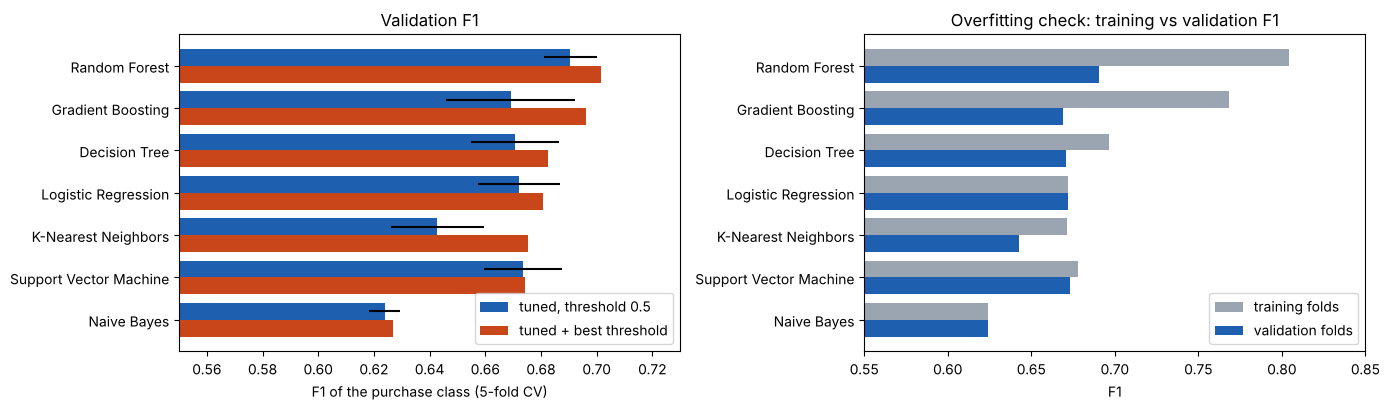

In [8]:
t = table.sort_values("Tuned F1 + best threshold")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ypos = np.arange(len(t))
axes[0].barh(ypos + 0.2, t["Tuned F1"], height=0.4, xerr=t["Tuned F1 std"], color="#1f5fb0", label="tuned, threshold 0.5")
axes[0].barh(ypos - 0.2, t["Tuned F1 + best threshold"], height=0.4, color="#c8461a", label="tuned + best threshold")
axes[0].set_yticks(ypos); axes[0].set_yticklabels(t["Model"]); axes[0].set_xlim(0.55, 0.73)
axes[0].set_xlabel("F1 of the purchase class (5-fold CV)"); axes[0].legend(loc="lower right"); axes[0].set_title("Validation F1")

axes[1].barh(ypos + 0.2, t["Train F1"], height=0.4, color="#9aa5b1", label="training folds")
axes[1].barh(ypos - 0.2, t["Tuned F1"], height=0.4, color="#1f5fb0", label="validation folds")
axes[1].set_yticks(ypos); axes[1].set_yticklabels(t["Model"]); axes[1].set_xlim(0.55, 0.85)
axes[1].set_xlabel("F1"); axes[1].legend(loc="lower right"); axes[1].set_title("Overfitting check: training vs validation F1")
plt.tight_layout(); plt.show()

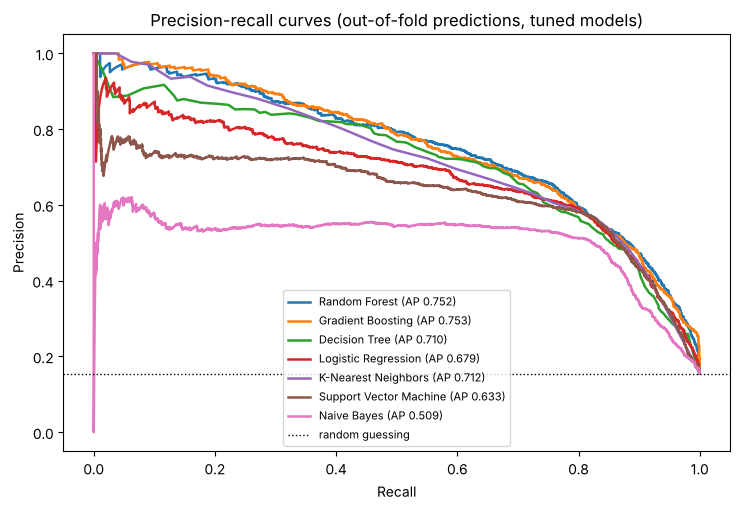

In [9]:
from sklearn.metrics import precision_recall_curve, average_precision_score
fig, ax = plt.subplots(figsize=(7.5, 5.2))
for name in table["Model"]:
    slug = name.lower().replace(" ", "_")
    oof = np.load(PROJECT / "results" / "oof" / f"{slug}_tuned.npy")
    p, r, _ = precision_recall_curve(y, oof)
    ax.plot(r, p, label=f"{name} (AP {average_precision_score(y, oof):.3f})", lw=1.8)
ax.axhline(y.mean(), color="k", ls=":", lw=1, label="random guessing")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-recall curves (out-of-fold predictions, tuned models)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**What we learned from each model**

| Model | Observation |
|---|---|
| Random Forest | Best model. Tuning (balanced class weights, `min_samples_leaf=5`, 500 trees) lifted F1 from 0.663 to 0.691. Its training F1 is much higher than its validation F1 (gap 0.11), which is typical of forests, but validation performance is still the best. |
| Gradient Boosting | Close second. Many small trees (depth 4, learning rate 0.03, 200 trees, subsample 0.8). Gap about 0.10. Tuning at the default 0.5 cut-off helped little; moving the threshold to 0.34 raised F1 from 0.669 to 0.696. |
| Logistic Regression | Strong for such a simple model (0.672). Train and validation F1 are identical, so it **underfits** rather than overfits. It needed strong regularization (`C=0.003`) and balanced class weights. |
| Decision Tree | The default (unlimited depth) tree badly overfits (baseline F1 0.577). Pruning to depth 5 with at least 50 rows per leaf gives 0.671 with a small gap. |
| Support Vector Machine | 0.673, no better than logistic regression, and by far the slowest to tune (the Grid Search took more than 2 minutes). Balanced class weights were important. |
| K-Nearest Neighbors | 0.643 at the default cut-off. Distances are less useful with about 70 one-hot and numeric features. A lower threshold helps (0.675). |
| Naive Bayes | Weakest (0.624). The independence assumption is clearly violated (page counts and durations are strongly related), and it needed an extremely large `var_smoothing` to work at all. |

Across models, the **gap between the best and the 5th best is small (about 0.02 F1)** compared with the fold-to-fold standard deviation (0.01 to 0.02), so small differences should not be over-interpreted. Models without class weights (Gradient Boosting, KNN, Decision Tree) gain more from lowering the decision threshold (+0.012 to +0.033 F1) than models with class weights (Random Forest, SVM, Logistic Regression: +0.001 to +0.011).

## 5. Final model selection: Random Forest

| Criterion | Random Forest | Alternatives |
|---|---|---|
| Validation performance | Highest tuned F1 (0.691 at the default cut-off) and lowest fold-to-fold variation among the top models (std 0.010); ROC AUC 0.933 | Gradient Boosting: 0.669 (0.696 with a tuned threshold), AUC 0.933. Logistic Regression: 0.672 |
| Overfitting | Train-validation gap of 0.11, larger than Logistic Regression (about 0). Reduced by averaging 500 trees and `min_samples_leaf=5`, and the nested cross-validation below shows its validation score is not an artifact of tuning | Logistic Regression does not overfit but it underfits |
| Complexity | 500 trees, few hyperparameters, robust to scaling and outliers | Gradient Boosting has more hyperparameters that interact (learning rate, trees, depth, subsample) |
| Compute | The Grid Search was slow (about 13 minutes on a teammate's computer), but fitting one final model takes seconds | SVM is the slowest to tune; Logistic Regression is the fastest |
| Interpretability | Less interpretable than Logistic Regression, but feature importance gives a clear picture (below) | Logistic Regression is the most interpretable |

Random Forest and Gradient Boosting are practically tied when GB uses a tuned threshold (0.702 vs 0.696, well within one standard deviation). We choose the Random Forest because it has the highest validation F1 **without** needing any post-hoc threshold adjustment, the most stable results across folds, and simpler tuning. Logistic Regression would be our choice if interpretability mattered more than about 0.02 F1.

In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_best = json.loads((PROJECT / "results" / "random_forest.json").read_text())["best_params"]
print("Best Random Forest parameters from Grid Search:", rf_best)

final_pipeline = make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, **rf_best), kind="tree")
cv_res, oof = cv_evaluate(final_pipeline, X, y)      # recomputed live with the shared 5 folds
print(f"5-fold CV  F1 = {cv_res['f1_mean']:.4f} +/- {cv_res['f1_std']:.4f}   "
      f"precision = {cv_res['precision_mean']:.3f}   recall = {cv_res['recall_mean']:.3f}   "
      f"ROC AUC = {cv_res['roc_auc_mean']:.3f}")
print(f"training-fold F1 = {cv_res['train_f1_mean']:.4f}  (gap to validation = {cv_res['train_f1_mean'] - cv_res['f1_mean']:.3f})")

Best Random Forest parameters from Grid Search: {'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 500}


5-fold CV  F1 = 0.6906 +/- 0.0096   precision = 0.616   recall = 0.787   ROC AUC = 0.933
training-fold F1 = 0.8043  (gap to validation = 0.114)


### Decision threshold

A Random Forest outputs a probability. We predict "purchase" when it is above a cut-off. The out-of-fold predictions suggest a slightly higher cut-off would give a slightly higher F1, but the curve is very flat. Section 6 checks whether that gain is real.

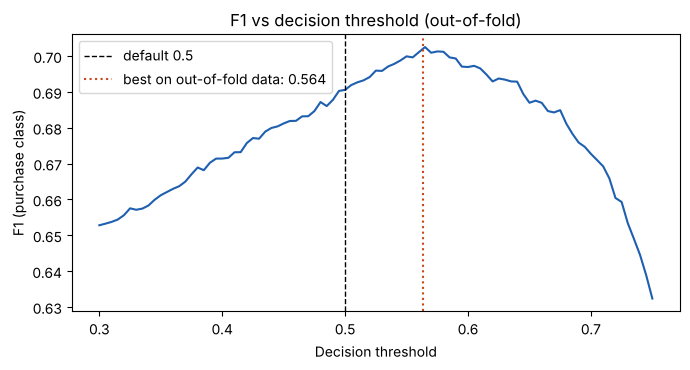

F1 at 0.5 = 0.6906   F1 at 0.564 = 0.7016   (difference +0.0110)


In [11]:
from sklearn.metrics import f1_score
thresholds = np.linspace(0.30, 0.75, 91)
f1_curve = [f1_score(y, oof >= t) for t in thresholds]
best_t, best_f1 = common.best_threshold(y.values, oof)
plt.figure(figsize=(7, 3.8))
plt.plot(thresholds, f1_curve, color="#1f5fb0")
plt.axvline(0.5, color="k", ls="--", lw=1, label="default 0.5")
plt.axvline(best_t, color="#c8461a", ls=":", lw=1.5, label=f"best on out-of-fold data: {best_t:.3f}")
plt.xlabel("Decision threshold"); plt.ylabel("F1 (purchase class)"); plt.legend(); plt.title("F1 vs decision threshold (out-of-fold)")
plt.tight_layout(); plt.show()
print(f"F1 at 0.5 = {f1_score(y, oof >= 0.5):.4f}   F1 at {best_t:.3f} = {best_f1:.4f}   (difference {best_f1 - f1_score(y, oof >= 0.5):+.4f})")

## 6. How well will it do on new data? Nested cross-validation

The scores above come from settings that were *selected* because they scored well on these folds, so they are slightly optimistic. `nested_cv_final.py` repeats the **entire procedure** (Grid Search over a neighborhood of the best settings, then choosing the cut-off) inside each of the 5 outer folds, using only the outer-training data, and scores on the outer fold that was never touched. (It takes about 3 to 15 minutes depending on the computer, so its saved result is loaded here: `python challenge2/nested_cv_final.py` reproduces it.)

In [12]:
nested = json.loads((PROJECT / "results" / "final_model_nested_cv.json").read_text())
display(pd.DataFrame(nested["folds"]).drop(columns=["best_params"]).round(4).style.hide(axis="index"))
print(f"Nested CV  F1 at 0.5                  = {nested['f1_at_0.5_mean']:.4f} +/- {nested['f1_at_0.5_std']:.4f}")
print(f"Nested CV  F1 with a tuned threshold  = {nested['f1_with_threshold_mean']:.4f} +/- {nested['f1_with_threshold_std']:.4f}")

fold,threshold,f1_at_0.5,f1_with_threshold,precision,recall
1,0.511000,0.703200,0.706900,0.678500,0.737800
2,0.474600,0.701100,0.700300,0.624000,0.797900
3,0.553500,0.686800,0.678400,0.685700,0.671300
4,0.510800,0.700700,0.696700,0.665600,0.730800
5,0.566500,0.681900,0.683700,0.629400,0.748300


Nested CV  F1 at 0.5                  = 0.6947 +/- 0.0097
Nested CV  F1 with a tuned threshold  = 0.6932 +/- 0.0118


**Conclusions from the nested cross-validation**
- The honest estimate of our final model's F1 is about **0.69** (0.695 +/- 0.010 at the default cut-off). The 0.702 in the comparison table was the optimistic "best of many" number.
- Choosing a custom threshold does **not** help the Random Forest (0.693 with it, 0.695 without). The flat curve above shows the gain from 0.5 to 0.56 was noise. The forest already uses balanced class weights, which does the same job.
- Therefore the **final predictions use the default 0.5 threshold**.

### Final model: confusion matrix and feature importance

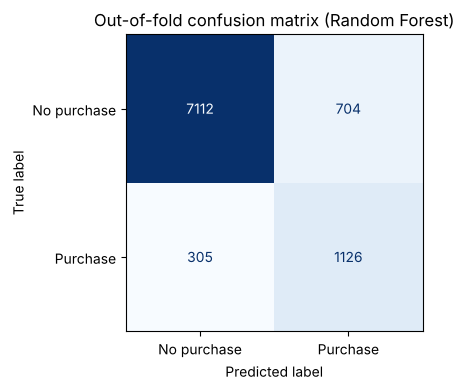

              precision    recall  f1-score   support

 No purchase      0.959     0.910     0.934      7816
    Purchase      0.615     0.787     0.691      1431

    accuracy                          0.891      9247
   macro avg      0.787     0.848     0.812      9247
weighted avg      0.906     0.891     0.896      9247



In [13]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
FINAL_THRESHOLD = 0.5
pred_oof = oof >= FINAL_THRESHOLD
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(y, pred_oof, display_labels=["No purchase", "Purchase"], cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Out-of-fold confusion matrix (Random Forest)"); plt.tight_layout(); plt.show()
print(classification_report(y, pred_oof, target_names=["No purchase", "Purchase"], digits=3))

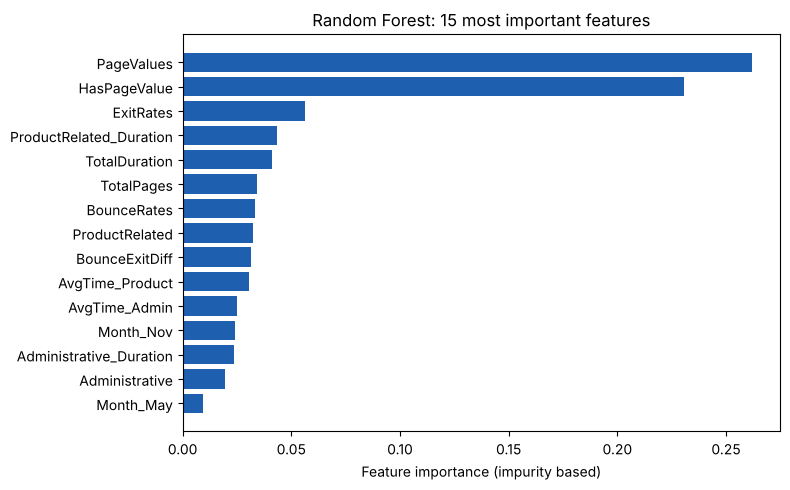

In [14]:
final_model = final_pipeline.fit(X, y)         # now train on ALL training data
names = final_model.named_steps["prep"].named_steps["columns"].get_feature_names_out()
importance = pd.Series(final_model.named_steps["model"].feature_importances_, index=names)
top = importance.sort_values().tail(15)
top.index = [n.split("__", 1)[1] for n in top.index]
plt.figure(figsize=(8, 5)); plt.barh(top.index, top.values, color="#1f5fb0")
plt.xlabel("Feature importance (impurity based)"); plt.title("Random Forest: 15 most important features")
plt.tight_layout(); plt.show()

`PageValues` and `HasPageValue` (which is derived from it) dominate, as the exploration suggested. The exit rate, session duration, and number of product pages come next, and the November / May seasonality shows up too. (Impurity-based importances can favor features with many distinct values, so we treat them as a rough guide, not proof of cause.)

## 7. Predictions for the test set

In [15]:
proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test = proba_test >= FINAL_THRESHOLD

submission = pd.DataFrame({"ID": test_ids, "Revenue": pred_test})     # True / False
submission.to_csv(PROJECT / "predictions.csv", index=False)

# sanity checks
check = pd.read_csv(PROJECT / "predictions.csv")
assert len(check) == len(X_test) == 3083
assert check["ID"].is_unique and set(check["ID"]) == set(test_ids)
assert list(check.columns) == ["ID", "Revenue"] and set(check["Revenue"]) <= {True, False}
print("predictions.csv written:", check.shape)
print(f"Predicted purchases in test set: {check['Revenue'].mean():.1%}   "
      f"(out-of-fold predicted rate in training data: {pred_oof.mean():.1%}; true rate: {y.mean():.1%})")
display(check.head())

predictions.csv written: (3083, 2)
Predicted purchases in test set: 19.0%   (out-of-fold predicted rate in training data: 19.8%; true rate: 15.5%)


,ID,Revenue
0,2,False
1,5,False
2,6,False
3,8,False
4,10,False


## Summary

- **Final model:** Random Forest (500 trees, balanced class weights, `min_samples_leaf=5`, unlimited depth), default 0.5 threshold, trained on all 9,247 training sessions.
- **Validation:** 5-fold stratified CV F1 = 0.691 +/- 0.010; nested CV estimate of F1 on new data about 0.69.
- **Limitations:** the models share one set of engineered features, so a different feature set could change the ranking; the top models are within about one standard deviation of each other; random forest feature importances are only a rough guide.